# Задание 2. Линейная регрессия (LinReg) и дисперсионный анализ (ANOVA)

Ноутбук самодостаточный: никаких локальных модулей, всё нужное определено в ячейках ниже,
поэтому он запускается в Google Colab как есть (**Runtime → Run all**).

Датасет — **Palmer Archipelago (Antarctica) penguins**: 3 вида пингвинов (классы) и 4
количественных признака, причём в нём есть настоящие пропуски — это делает пункты [2.3]–[2.5]
содержательными.

Все настраиваемые пользователем параметры собраны в двух ячейках-формах: «Параметры» и
«Стиль графиков». В Colab они отображаются как поля/переключатели; после изменения
достаточно перезапустить ячейки ниже.

In [1]:
# @title Установка и импорт
import importlib.util, subprocess, sys
for pkg in ("statsmodels", "seaborn"):          # в Colab оба уже есть; локально — доустановим
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import itertools
import warnings
from dataclasses import dataclass, replace
from typing import Optional, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import AutoMinorLocator, MaxNLocator, MultipleLocator
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
%matplotlib inline

In [2]:
# @title Параметры
# --- [2.4] классы и признаки ----------------------------------------------------
CLASS_COL = "species"
CLASSES   = ["Adelie", "Chinstrap", "Gentoo"]
FEATURES  = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

# --- [2.7] одиночный scatterplot с регрессией ----------------------------------------
REG_CLASS = "Gentoo"              # @param ["Adelie", "Chinstrap", "Gentoo"]
REG_X     = "flipper_length_mm"   # @param ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
REG_Y     = "body_mass_g"         # @param ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
SHOW_REG_LINE  = True             # @param {type:"boolean"}
SHOW_CONF_BAND = True             # @param {type:"boolean"}
SHOW_PRED_BAND = True             # @param {type:"boolean"}
CONF_LEVEL     = 0.95             # @param {type:"slider", min:0.80, max:0.99, step:0.01}

# --- [2.8] матрица пар с регрессиями ----------------------------------------------
MATRIX_SHOW_PRED_BAND = True      # @param {type:"boolean"}
MATRIX_SHOW_CONF_BAND = False     # @param {type:"boolean"}

# --- [2.10] raincloud ------------------------------------------------------------
RAIN_FEATURE = "body_mass_g"      # @param ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
RAIN_CI      = "median (bootstrap)"  # @param ["median (bootstrap)", "mean (t)"]

# --- [2.11] ANOVA ----------------------------------------------------------------
ANOVA_FEATURE = "bill_length_mm"  # @param ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

assert REG_X != REG_Y, "Для регрессии нужны два разных признака"
ALPHA = 1 - CONF_LEVEL

In [3]:
# @title Стиль графиков (регулируется пользователем)
AXIS_COLOR      = "#3A3A3A"  # @param {type:"string"}
AXIS_LINEWIDTH  = 1.1        # @param {type:"slider", min:0.2, max:4, step:0.1}
N_MAJOR_TICKS   = 6          # @param {type:"integer"}
MAJOR_STEP      = 0          # @param {type:"number"}
N_MINOR         = 4          # @param {type:"integer"}
GRID_MAJOR      = True       # @param {type:"boolean"}
GRID_MINOR      = False      # @param {type:"boolean"}
SQUARE_CELLS    = True       # @param {type:"boolean"}
FONT_FAMILY     = "DejaVu Sans"  # @param ["DejaVu Sans", "DejaVu Serif", "DejaVu Sans Mono"]
TITLE_FONTSIZE  = 12         # @param {type:"integer"}
LABEL_FONTSIZE  = 10         # @param {type:"integer"}
TICK_FONTSIZE   = 9          # @param {type:"integer"}
LEGEND_FONTSIZE = 9          # @param {type:"integer"}
SHOW_TITLES     = True       # @param {type:"boolean"}
SHOW_LEGENDS    = True       # @param {type:"boolean"}
POINT_ALPHA     = 0.6        # @param {type:"slider", min:0.05, max:1, step:0.05}
POINT_SIZE      = 20         # @param {type:"integer"}

## Вспомогательный код

Стиль, таблицы статистики, heat-map корреляций, UpSet-график, матрица пар, регрессия и тесты,
raincloud, ANOVA. Сценарий по пунктам — ниже.

In [4]:
# @title Стиль: PlotStyle и оформление осей
PALETTE = ("#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860")
MARKERS = ("o", "s", "^", "D", "v", "P")


@dataclass
class PlotStyle:
    cell: float = 2.8
    square_cells: bool = True
    dpi: int = 100
    font_family: str = "DejaVu Sans"
    axis_color: str = "#3A3A3A"
    axis_linewidth: float = 1.1
    visible_spines: Sequence[str] = ("left", "bottom")
    n_major: int = 5
    major_step: Optional[float] = None
    n_minor: int = 4
    tick_labelsize: float = 8
    major_tick_len: float = 4.0
    minor_tick_len: float = 2.0
    grid_major: bool = True
    grid_minor: bool = False
    grid_color: str = "#C9C9C9"
    grid_alpha: float = 0.7
    show_suptitle: bool = True
    show_title: bool = True
    show_axis_labels: bool = True
    show_legend: bool = True
    suptitle_fontsize: float = 14
    title_fontsize: float = 10
    axis_label_fontsize: float = 9.5
    legend_fontsize: float = 9
    label_color: str = "#1A1A1A"
    point_size: float = 18
    point_alpha: float = 0.6
    palette: Sequence[str] = PALETTE
    markers: Sequence[str] = MARKERS
    density_alpha: float = 0.30
    line_width: float = 1.8
    conf_alpha: float = 0.35
    pred_alpha: float = 0.13

    def colors_for(self, levels):
        return {lv: self.palette[i % len(self.palette)] for i, lv in enumerate(levels)}

    def markers_for(self, levels):
        return {lv: self.markers[i % len(self.markers)] for i, lv in enumerate(levels)}

    def derive(self, **kw):
        return replace(self, **kw)


def apply_axes_style(ax, st: PlotStyle, square: Optional[bool] = None):
    for name, spine in ax.spines.items():
        spine.set_visible(name in st.visible_spines)
        spine.set_color(st.axis_color)
        spine.set_linewidth(st.axis_linewidth)
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(MultipleLocator(st.major_step) if st.major_step
                               else MaxNLocator(nbins=st.n_major))
        if st.n_minor and st.n_minor > 1:
            axis.set_minor_locator(AutoMinorLocator(st.n_minor))
    ax.tick_params(which="major", labelsize=st.tick_labelsize, colors=st.axis_color,
                   length=st.major_tick_len, width=st.axis_linewidth * 0.9)
    ax.tick_params(which="minor", length=st.minor_tick_len, width=st.axis_linewidth * 0.7,
                   colors=st.axis_color)
    ax.set_axisbelow(True)
    # свойства линий передаём только при включении сетки: grid(False, color=...) её включает
    if st.grid_major:
        ax.grid(True, which="major", color=st.grid_color, linewidth=0.6, alpha=st.grid_alpha)
    else:
        ax.grid(False, which="major")
    if st.grid_minor:
        ax.grid(True, which="minor", color=st.grid_color, linestyle=":", linewidth=0.45,
                alpha=st.grid_alpha * 0.7)
    else:
        ax.grid(False, which="minor")
    if square if square is not None else st.square_cells:
        ax.set_box_aspect(1)


def class_legend(fig_or_ax, levels, st, title=CLASS_COL, extra=(), **kw):
    colors, markers = st.colors_for(levels), st.markers_for(levels)
    handles = [Line2D([], [], linestyle="none", marker=markers[lv], color=colors[lv],
                      markersize=7, label=str(lv)) for lv in levels] + list(extra)
    return fig_or_ax.legend(handles=handles, title=title, fontsize=st.legend_fontsize,
                            title_fontsize=st.legend_fontsize, frameon=False, **kw)


STYLE = PlotStyle(
    square_cells=SQUARE_CELLS, font_family=FONT_FAMILY,
    axis_color=AXIS_COLOR, axis_linewidth=AXIS_LINEWIDTH,
    n_major=N_MAJOR_TICKS, major_step=(MAJOR_STEP or None), n_minor=N_MINOR,
    grid_major=GRID_MAJOR, grid_minor=GRID_MINOR,
    suptitle_fontsize=TITLE_FONTSIZE + 2, title_fontsize=TITLE_FONTSIZE,
    axis_label_fontsize=LABEL_FONTSIZE, tick_labelsize=TICK_FONTSIZE,
    legend_fontsize=LEGEND_FONTSIZE,
    show_title=SHOW_TITLES, show_suptitle=SHOW_TITLES, show_legend=SHOW_LEGENDS,
    point_alpha=POINT_ALPHA, point_size=POINT_SIZE,
)
plt.rcParams["font.family"] = STYLE.font_family

In [5]:
# @title Статистика [2.2] и heat-map корреляций [2.5]
def describe_dataset(df, class_col, features, zero_atol=1e-12):
    values, classes = df[features], df[class_col]
    shape = pd.DataFrame({"значение": [len(df), df.shape[1], len(features), classes.nunique()]},
                         index=["объекты (строки)", "столбцы", "количественные признаки", "классы"])
    dtypes = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "роль": ["класс" if c == class_col else ("количественный" if c in features else "категориальный")
                 for c in df.columns],
        "уникальных": df.nunique(dropna=True),
        "непустых": df.notna().sum(),
    })
    counts = classes.value_counts().sort_index()
    class_table = pd.DataFrame({"объектов": counts, "доля, %": (counts / len(df) * 100).round(2)})

    summary = values.describe().T
    summary["IQR"] = summary["75%"] - summary["25%"]
    summary["range"] = summary["max"] - summary["min"]
    summary["skew"] = values.skew()
    summary["kurtosis"] = values.kurtosis()
    summary["missing"] = values.isna().sum()

    na = df.drop(columns=class_col).isna().groupby(classes).sum()
    na["строк с ≥1 NaN"] = df.drop(columns=class_col).isna().any(axis=1).groupby(classes).sum()
    na["строк без NaN"] = df.drop(columns=class_col).notna().all(axis=1).groupby(classes).sum()

    zeros = (values.abs() <= zero_atol).groupby(classes).sum()
    zeros["строк с ≥1 нулём"] = (values.abs() <= zero_atol).any(axis=1).groupby(classes).sum()

    return {
        "Размерность": shape,
        "Типы признаков": dtypes,
        "Классы и объекты в классах": class_table,
        "Оценки выборки (количественные признаки)": summary.round(3),
        "Число объектов с NaN по классам": na,
        "Число объектов с 0 по классам": zeros,
    }


def show_tables(tables):
    for caption, table in tables.items():
        display(Markdown(f"**{caption}**"))
        display(table)


def pearson_tables(df, features, class_col, label=""):
    out = {f"{label}весь датасет": df[features].corr("pearson")}
    for name, part in df.groupby(class_col, observed=True):
        out[f"{label}{name}"] = part[features].corr("pearson")
    return out


def plot_heatmaps(tables, ncols=4, cell=3.1, cmap="RdBu_r", vmin=-1, vmax=1, suptitle=None,
                  short=None, fmt="{:.2f}"):
    items = list(tables.items())
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(cell * ncols + 1.2, cell * nrows), squeeze=False)
    mesh = None
    for ax, (title, m) in zip(axes.ravel(), items):
        data = m.to_numpy(float)
        labels = [short.get(c, c) for c in m.columns] if short else list(m.columns)
        mesh = ax.imshow(data, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_xticks(range(len(labels)), labels, fontsize=8, rotation=30, ha="right")
        ax.set_yticks(range(len(labels)), labels, fontsize=8)
        ax.set_title(title, fontsize=10)
        ax.tick_params(length=0)
        for s in ax.spines.values():
            s.set_visible(False)
        span = max(abs(vmin), abs(vmax))
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                v = data[i, j]
                if not np.isnan(v):
                    ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8,
                            color="white" if abs(v) > 0.6 * span else "#111")
    for ax in axes.ravel()[len(items):]:
        ax.set_visible(False)
    fig.subplots_adjust(wspace=0.4)
    fig.colorbar(mesh, ax=axes, fraction=0.025, pad=0.02)
    if suptitle:
        fig.suptitle(suptitle, fontsize=13, y=1.0, va="bottom")
    plt.show()


SHORT = {"bill_length_mm": "bill_len", "bill_depth_mm": "bill_dep",
         "flipper_length_mm": "flipper", "body_mass_g": "mass"}

In [6]:
# @title UpSet-график [2.3] (собственная реализация на matplotlib)
def upset_plot(indicators: pd.DataFrame, title: str, color="#4C72B0", sort_by="cardinality",
               max_intersections: Optional[int] = None, show_empty=False):
    '''UpSet по булевой таблице «объект × условие».

    Верхние столбцы — число объектов в каждом пересечении (комбинации условий, выполненных
    одновременно и только они), точки внизу — какие условия входят в пересечение, слева —
    сколько объектов выполняют условие всего. Условия без единого объекта не выбрасываются
    (в отличие от upsetplot), а остаются в матрице с итогом 0.
    '''
    ind = indicators.astype(bool)
    names = list(ind.columns)
    combos = ind.value_counts(sort=False)
    combos.index = [tuple(k) if isinstance(k, tuple) else (k,) for k in combos.index]
    empty = tuple([False] * len(names))
    n_none = int(combos.get(empty, 0))
    if not show_empty:
        combos = combos[[k != empty for k in combos.index]]
    if combos.empty:
        print(f"[{title}] ни один объект не выполняет ни одного условия — график не нужен.")
        return None
    if sort_by == "cardinality":
        combos = combos.sort_values(ascending=False, kind="stable")
    else:  # "degree": по числу условий в пересечении, затем по размеру
        combos = combos.iloc[sorted(range(len(combos)),
                                    key=lambda i: (sum(combos.index[i]), -combos.iloc[i]))]
    if max_intersections:
        combos = combos.iloc[:max_intersections]

    k, m = len(names), len(combos)
    lab_w = 0.085 * max(map(len, map(str, names))) + 0.2      # отдельная колонка под подписи
    fig = plt.figure(figsize=(1.6 + lab_w + 0.48 * max(m, 4), 2.9 + 0.42 * k))
    gs = fig.add_gridspec(2, 3, width_ratios=[1.6, lab_w, 0.48 * max(m, 4)],
                          height_ratios=[2.6, 0.42 * k], wspace=0.0, hspace=0.05)
    ax_bar, ax_mat = fig.add_subplot(gs[0, 2]), fig.add_subplot(gs[1, 2])
    ax_tot, ax_lab = fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])

    x = np.arange(m)
    ax_bar.bar(x, combos.to_numpy(), width=0.62, color=color)
    for xi, v in zip(x, combos.to_numpy()):
        ax_bar.text(xi, v, str(v), ha="center", va="bottom", fontsize=8)
    ax_bar.set_xlim(-0.6, m - 0.4)
    ax_bar.set_xticks([])
    ax_bar.set_ylabel("объектов в пересечении", fontsize=9)
    for s in ("top", "right"):
        ax_bar.spines[s].set_visible(False)

    y = np.arange(k)[::-1]  # первое условие — сверху
    for yi in y[::2]:
        ax_mat.axhspan(yi - 0.5, yi + 0.5, color="#F2F2F2", zorder=0)
    for xi, key in zip(x, combos.index):
        on = [yy for yy, flag in zip(y, key) if flag]
        ax_mat.scatter([xi] * k, y, s=70, color="#DDDDDD", zorder=1)
        if on:
            ax_mat.scatter([xi] * len(on), on, s=70, color=color, zorder=3)
            ax_mat.vlines(xi, min(on), max(on), color=color, linewidth=2.2, zorder=2)
    ax_mat.set_xlim(-0.6, m - 0.4)
    ax_mat.set_ylim(-0.5, k - 0.5)
    ax_mat.set_xticks([])
    ax_mat.set_yticks([])
    ax_lab.set_ylim(-0.5, k - 0.5)
    ax_lab.axis("off")
    for yi, name in zip(y, names):
        ax_lab.text(0.5, yi, name, ha="center", va="center", fontsize=9)
    for s in ax_mat.spines.values():
        s.set_visible(False)

    totals = ind.sum().to_numpy()
    ax_tot.barh(y, totals, height=0.55, color=color, alpha=0.6)
    ax_tot.set_ylim(-0.5, k - 0.5)
    ax_tot.invert_xaxis()
    ax_tot.set_yticks([])
    ax_tot.set_xlabel("всего по условию", fontsize=9)
    for yi, v in zip(y, totals):
        ax_tot.text(v, yi, f"{v} ", ha="right", va="center", fontsize=8)
    for s in ("top", "left", "right"):
        ax_tot.spines[s].set_visible(False)
    ax_tot.margins(x=0.25)

    fig.suptitle(f"{title}\n(объектов вне всех условий: {n_none} из {len(ind)})", fontsize=12, y=1.02)
    plt.show()
    return combos

In [7]:
# @title Линейная регрессия и тесты [2.7]–[2.9]
def fit_linreg(x, y, alpha=0.05, grid_n=200):
    '''OLS y = b0 + b1·x, полосы на сетке x, тесты Вальда / LR / score для H0: b1 = 0.'''
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = ~(np.isnan(x) | np.isnan(y))
    x, y = x[ok], y[ok]
    res = sm.OLS(y, sm.add_constant(x)).fit()
    res0 = sm.OLS(y, np.ones_like(y)).fit()           # ограниченная модель: только свободный член
    grid = np.linspace(x.min(), x.max(), grid_n)
    bands = res.get_prediction(sm.add_constant(grid)).summary_frame(alpha=alpha)
    return {"res": res, "res0": res0, "x": x, "y": y, "grid": grid, "bands": bands,
            "b0": res.params[0], "b1": res.params[1], "r2": res.rsquared, "n": int(res.nobs),
            "tests": trinity_tests(res, res0)}


def trinity_tests(res, res0):
    '''Wald, LR и score (LM) для вложенных моделей с нормальными ошибками.

    W  = n·(RSS0 − RSS1)/RSS1,   LR = n·ln(RSS0/RSS1),   LM = n·(RSS0 − RSS1)/RSS0,
    асимптотически χ²(q). F-форма каждого: F = stat·(n − k)/(n·q) ~ F(q, n − k);
    для Вальда это в точности классический F-критерий регрессии.
    '''
    n, k = res.nobs, res.df_model + 1
    q = res.df_model
    rss1, rss0 = res.ssr, res0.ssr
    raw = {"Wald": n * (rss0 - rss1) / rss1,
           "LR": n * np.log(rss0 / rss1),
           "score": n * (rss0 - rss1) / rss0}
    out = {}
    for name, stat in raw.items():
        F = stat * (n - k) / (n * q)
        out[name] = {"chi2": stat, "p(chi2)": stats.chi2.sf(stat, q),
                     "F": F, "df1": int(q), "df2": int(n - k), "p(F)": stats.f.sf(F, q, n - k)}
    # сверка со statsmodels
    assert np.isclose(out["Wald"]["F"], res.fvalue)
    assert np.isclose(out["LR"]["chi2"], res.compare_lr_test(res0)[0])
    assert np.isclose(out["score"]["chi2"], res.compare_lm_test(res0)[0])
    return out


def formula(fit, xname, yname, digits=4):
    b0, b1 = fit["b0"], fit["b1"]
    sign = "+" if b1 >= 0 else "−"
    return f"{yname} = {b0:.{digits}g} {sign} {abs(b1):.{digits}g}·{xname}"


def draw_fit(ax, fit, color, st, line=True, conf=True, pred=True, label=None):
    g, b = fit["grid"], fit["bands"]
    if pred:
        ax.fill_between(g, b["obs_ci_lower"], b["obs_ci_upper"], color=color,
                        alpha=st.pred_alpha, linewidth=0, zorder=1)
        ax.plot(g, b["obs_ci_lower"], g, b["obs_ci_upper"], color=color, linewidth=0.6,
                linestyle="--", alpha=0.7, zorder=1)
    if conf:
        ax.fill_between(g, b["mean_ci_lower"], b["mean_ci_upper"], color=color,
                        alpha=st.conf_alpha, linewidth=0, zorder=2)
    if line:
        ax.plot(g, b["mean"], color=color, linewidth=st.line_width, zorder=4, label=label)


def tests_row(fit, cls, xname, yname):
    row = {"класс": cls, "y": yname, "x": xname, "n": fit["n"],
           "формула": formula(fit, SHORT.get(xname, xname), SHORT.get(yname, yname)),
           "R²": fit["r2"]}
    for name, t in fit["tests"].items():
        row[(name, "F")] = t["F"]
        row[(name, "df1")] = t["df1"]
        row[(name, "df2")] = t["df2"]
        row[(name, "p")] = t["p(F)"]
    return row

In [8]:
# @title Матрица пар [2.6] / [2.8]
def kde_line(v, n=200):
    v = np.asarray(v, float)
    v = v[~np.isnan(v)]
    if v.size < 2 or np.allclose(v, v[0]):
        return np.array([]), np.array([])
    pad = 0.1 * np.ptp(v)
    grid = np.linspace(v.min() - pad, v.max() + pad, n)
    return grid, stats.gaussian_kde(v)(grid)


def pair_matrix(df, features, class_col, st: PlotStyle, suptitle=None, regression=False,
                show_conf=False, show_pred=True, alpha=0.05):
    levels = list(pd.unique(df[class_col].dropna()))
    levels = [c for c in CLASSES if c in levels] + [c for c in levels if c not in CLASSES]
    colors, markers = st.colors_for(levels), st.markers_for(levels)
    k = len(features)
    fig, axes = plt.subplots(k, k, figsize=(st.cell * k, st.cell * k), dpi=st.dpi, squeeze=False)
    fits = {}
    for i, yf in enumerate(features):
        for j, xf in enumerate(features):
            ax = axes[i, j]
            for lv in levels:
                part = df[df[class_col] == lv]
                if i == j:
                    g, d = kde_line(part[xf])
                    if g.size:
                        ax.fill_between(g, 0, d, color=colors[lv], alpha=st.density_alpha, linewidth=0)
                        ax.plot(g, d, color=colors[lv], linewidth=1.4)
                else:
                    ax.scatter(part[xf], part[yf], s=st.point_size * 0.7, color=colors[lv],
                               marker=markers[lv], alpha=st.point_alpha, linewidths=0, zorder=3)
                    if regression:
                        fit = fit_linreg(part[xf], part[yf], alpha=alpha)
                        fits[(lv, xf, yf)] = fit
                        draw_fit(ax, fit, colors[lv], st, conf=show_conf, pred=show_pred)
            apply_axes_style(ax, st)
            if i == j:
                ax.set_yticks([])
                ax.yaxis.set_minor_locator(plt.NullLocator())
            if i < k - 1:
                ax.set_xticklabels([])
            if j > 0 and i != j:
                ax.tick_params(axis="y", which="both", labelleft=False)
            if i == 0 and j == k - 1:   # у первой строки слева плотность — шкалу y даём справа
                ax.tick_params(labelright=True)
            if st.show_axis_labels:
                if i == k - 1:
                    ax.set_xlabel(xf, fontsize=st.axis_label_fontsize, color=st.label_color)
                if j == 0:
                    ax.set_ylabel(yf if i != j else f"{yf}\n(плотность)",
                                  fontsize=st.axis_label_fontsize, color=st.label_color)
    if st.show_legend:
        extra = []
        if regression:
            extra.append(Line2D([], [], color="#555", linewidth=st.line_width, label="линия регрессии"))
            if show_conf:
                extra.append(Patch(color="#555", alpha=st.conf_alpha, label=f"доверит. {1-alpha:.0%}"))
            if show_pred:
                extra.append(Patch(color="#555", alpha=st.pred_alpha * 2, label=f"прогнозная {1-alpha:.0%}"))
        class_legend(fig, levels, st, extra=extra, loc="upper left", bbox_to_anchor=(0.94, 0.89))
    if suptitle and st.show_suptitle:
        fig.suptitle(suptitle, fontsize=st.suptitle_fontsize, color=st.label_color, y=0.92)
    fig.subplots_adjust(wspace=0.12, hspace=0.12)
    plt.show()
    return fits

In [9]:
# @title Raincloud с доверительными интервалами [2.10]
def ci_of(v, kind, level=0.95, n_boot=5000, seed=0):
    v = np.asarray(v, float)
    if kind.startswith("mean"):
        m, se = v.mean(), stats.sem(v)
        h = se * stats.t.ppf(0.5 + level / 2, v.size - 1)
        return m, m - h, m + h
    rng = np.random.default_rng(seed)
    boots = np.median(rng.choice(v, size=(n_boot, v.size), replace=True), axis=1)
    lo, hi = np.quantile(boots, [0.5 - level / 2, 0.5 + level / 2])
    return float(np.median(v)), float(lo), float(hi)


def raincloud_by_class(df, feature, class_col, st: PlotStyle, ci_kind="median (bootstrap)",
                       level=0.95, seed=0):
    levels = [c for c in CLASSES if c in set(df[class_col])]
    colors = st.colors_for(levels)
    rng = np.random.default_rng(seed)
    fig, ax = plt.subplots(figsize=(st.cell * 3, st.cell * 1.7), dpi=st.dpi)
    rows = []
    for i, lv in enumerate(levels):
        v = df.loc[df[class_col] == lv, feature].dropna().to_numpy(float)
        c = colors[lv]
        g, d = kde_line(v)                                     # облако: полу-скрипка справа
        d = d / d.max() * 0.38
        ax.fill_betweenx(g, i, i + d, color=c, alpha=st.density_alpha, linewidth=0)
        ax.plot(i + d, g, color=c, linewidth=1.3)
        ax.scatter(i - 0.30 + rng.uniform(-0.12, 0.12, v.size), v, s=st.point_size * 0.6,
                   color=c, alpha=st.point_alpha, linewidths=0, zorder=2)   # дождь: jitter слева
        q1, med, q3 = np.percentile(v, [25, 50, 75])
        est, lo, hi = ci_of(v, ci_kind, level, seed=seed)
        xb, w = i - 0.07, 0.10                                 # ящик между дождём и облаком
        ax.add_patch(plt.Rectangle((xb - w / 2, q1), w, q3 - q1, facecolor="white",
                                   edgecolor=c, linewidth=1.3, zorder=4))
        ax.add_patch(plt.Rectangle((xb - w / 4, lo), w / 2, hi - lo, facecolor=c,
                                   edgecolor="none", alpha=0.85, zorder=5))
        ax.hlines(med, xb - w / 2, xb + w / 2, color="#111", linewidth=2.2, zorder=6)
        if ci_kind.startswith("mean"):
            ax.plot(xb, est, marker="D", color="white", markeredgecolor="#111", markersize=5, zorder=7)
        ax.annotate(f"Me={med:.4g}", (xb + w / 2, med), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=st.tick_labelsize, color="#111", zorder=8)
        rows.append({"класс": lv, "n": v.size, "медиана": med, "Q1": q1, "Q3": q3, "IQR": q3 - q1,
                     "оценка для ДИ": est, f"ДИ {level:.0%}: низ": lo, f"ДИ {level:.0%}: верх": hi})
    apply_axes_style(ax, st, square=False)
    ax.set_xticks(range(len(levels)), levels, fontsize=st.axis_label_fontsize)
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.grid(False, axis="x", which="both")
    ax.set_xlim(-0.65, len(levels) - 0.45)
    if st.show_axis_labels:
        ax.set_ylabel(feature, fontsize=st.axis_label_fontsize, color=st.label_color)
    if st.show_legend:
        ax.legend(handles=[
            Patch(facecolor="white", edgecolor="#333", label="IQR (Q1–Q3)"),
            Line2D([], [], color="#111", linewidth=2.2, label="медиана"),
            Patch(color="#555", alpha=0.85, label=f"ДИ {level:.0%}: {ci_kind}"),
        ], fontsize=st.legend_fontsize, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    if st.show_title:
        ax.set_title(f"[2.10] Raincloud: {feature} по классам", fontsize=st.title_fontsize)
    plt.show()
    return pd.DataFrame(rows).set_index("класс")

## [2.1] Выбор датасета df0

Palmer penguins: 344 пингвина трёх видов (`species`: Adelie, Chinstrap, Gentoo), два
категориальных признака (`island`, `sex`) и четыре количественных измерения:
длина и глубина клюва (мм), длина крыла (мм), масса тела (г). Все четыре — непрерывные
физические величины; длина крыла и масса просто записаны с округлением до 1 мм и 25 г.

In [10]:
try:
    df0 = sns.load_dataset("penguins")
except Exception:   # запасной источник, если репозиторий seaborn-data недоступен
    url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"
    df0 = pd.read_csv(url).drop(columns="year", errors="ignore")
    df0["sex"] = df0["sex"].str.upper()
df0.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


## [2.2] Статистика по датасету (как в [1.2])

In [11]:
show_tables(describe_dataset(df0, CLASS_COL, FEATURES))

**Размерность**

,значение
объекты (строки),344
столбцы,7
количественные признаки,4
классы,3


**Типы признаков**

,dtype,роль,уникальных,непустых
species,object,класс,3,344
island,object,категориальный,3,344
bill_length_mm,float64,количественный,164,342
bill_depth_mm,float64,количественный,80,342
flipper_length_mm,float64,количественный,55,342
body_mass_g,float64,количественный,94,342
sex,object,категориальный,2,333


**Классы и объекты в классах**

...

,count,mean,std,min,25%,50%,75%,max,IQR,range,skew,kurtosis,missing
bill_length_mm,342.0,43.922,5.460,32.1,39.225,44.45,48.5,59.6,9.275,27.5,0.053,-0.876,2
bill_depth_mm,342.0,17.151,1.975,13.1,15.600,17.30,18.7,21.5,3.100,8.4,-0.143,-0.907,2
flipper_length_mm,342.0,200.915,14.062,172.0,190.000,197.00,213.0,231.0,23.000,59.0,0.346,-0.984,2
body_mass_g,342.0,4201.754,801.955,2700.0,3550.000,4050.00,4750.0,6300.0,1200.000,3600.0,0.470,-0.719,2


**Число объектов с NaN по классам**

,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,строк с ≥1 NaN,строк без NaN
species,,,,,,,,
Adelie,0,1,1,1,1,6,6,146
Chinstrap,0,0,0,0,0,0,0,68
Gentoo,0,1,1,1,1,5,5,119


**Число объектов с 0 по классам**

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,строк с ≥1 нулём
species,,,,,
Adelie,0,0,0,0,0
Chinstrap,0,0,0,0,0
Gentoo,0,0,0,0,0


## [2.3] UpSet-графики для всего датасета

**(а) Пропуски.** Условие для признака — «значение отсутствует». Пересечение — набор
признаков, пропавших у объекта одновременно (и только их). Учитываются все 7 столбцов.

**(б) Повторы внутри признака.** Условие для признака — «значение объекта по этому признаку
совпадает со значением хотя бы одного другого объекта» (`duplicated(keep=False)`, пропуски не
считаются повтором). Пересечение — признаки, по которым объект одновременно имеет «двойников».
Берём четыре количественных признака: для категориальных повторы тривиальны (3 вида, 3 острова,
2 пола — повторяются все).

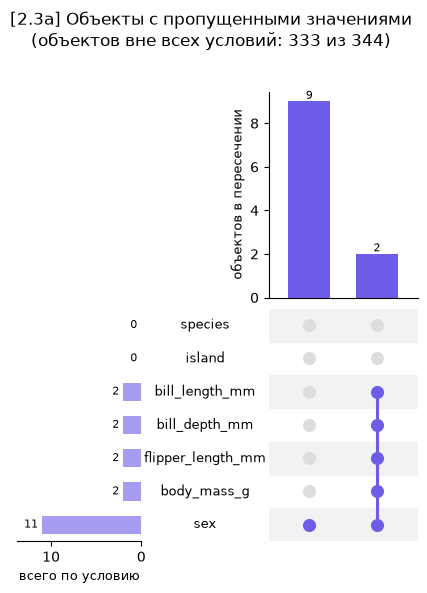

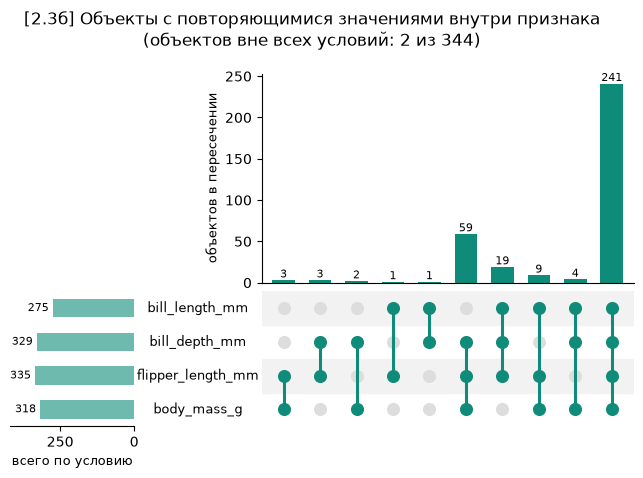

,пропусков,повторяющихся значений
species,0,0.0
island,0,0.0
bill_length_mm,2,275.0
bill_depth_mm,2,329.0
flipper_length_mm,2,335.0
body_mass_g,2,318.0
sex,11,0.0


In [12]:
missing = df0.isna()
_ = upset_plot(missing, "[2.3а] Объекты с пропущенными значениями", color="#6C5CE7")

dup = pd.DataFrame({f: df0[f].duplicated(keep=False) & df0[f].notna() for f in FEATURES})
_ = upset_plot(dup, "[2.3б] Объекты с повторяющимися значениями внутри признака", color="#0F8C79",
               sort_by="degree")
display(pd.DataFrame({"пропусков": missing.sum(), "повторяющихся значений": dup.reindex(columns=df0.columns).sum()})
        .fillna("—"))

Пропуски (а) устроены просто: у **двух** пингвинов (по одному Adelie и Gentoo) не измерено
вообще ничего — все четыре количественных признака и пол пропущены вместе; ещё у 9 объектов не
указан только пол. Это «блочный» пропуск, а не случайный по ячейкам.

Повторы (б) массовые: измерения записаны с шагом 0.1 мм / 1 мм / 25 г, поэтому при 342 объектах
совпадения неизбежны: от 275 (длина клюва, 164 уникальных значения) до 335 (длина крыла, всего
55 уникальных значений) из 342 объектов имеют «двойника», и самое большое пересечение — объекты,
повторяющиеся сразу по всем четырём признакам.

## [2.4] Отфильтрованный датасет df0m

Три класса — все три вида; четыре признака — `FEATURES`. Удаляем объекты, у которых не определено
значение хотя бы одного из этих четырёх признаков. Пропуск в `sex` основанием для удаления **не**
является: этот признак в анализ не входит.

In [13]:
df0m = (df0[df0[CLASS_COL].isin(CLASSES)]
        .dropna(subset=FEATURES)[[CLASS_COL] + FEATURES]
        .reset_index(drop=True))
df0m[CLASS_COL] = pd.Categorical(df0m[CLASS_COL], categories=CLASSES)

removed = df0.loc[df0[FEATURES].isna().any(axis=1)]
print(f"df0: {df0.shape}  →  df0m: {df0m.shape};  удалено объектов: {len(removed)}")
display(removed)
display(df0m[CLASS_COL].value_counts().sort_index().to_frame("объектов в df0m"))

df0: (344, 7)  →  df0m: (342, 5);  удалено объектов: 2


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


,объектов в df0m
species,
Adelie,151
Chinstrap,68
Gentoo,123


## [2.5] Корреляции Пирсона: df0 и df0m

В df0 корреляция каждой пары считается по объектам, где оба значения есть (pairwise deletion),
в df0m — по полностью заполненным объектам (listwise deletion). Третья строка — разность
df0m − df0 в своей, суженной цветовой шкале.

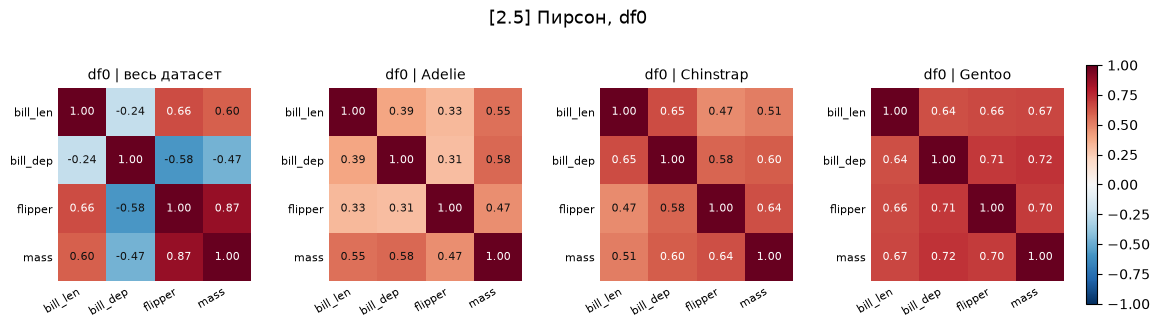

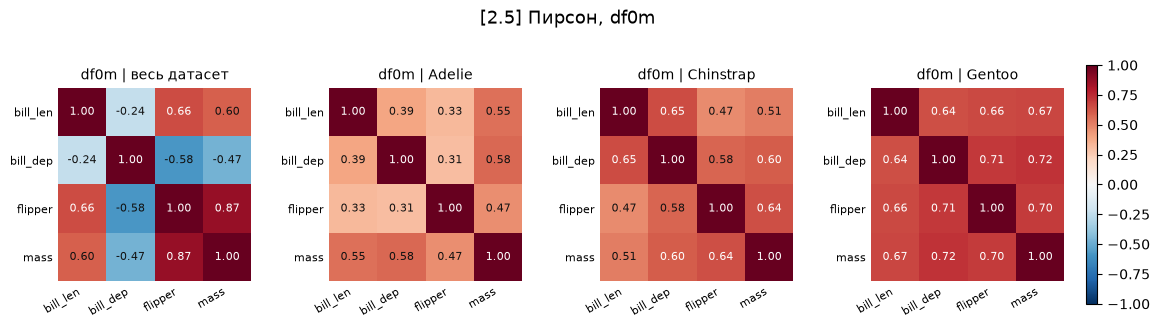

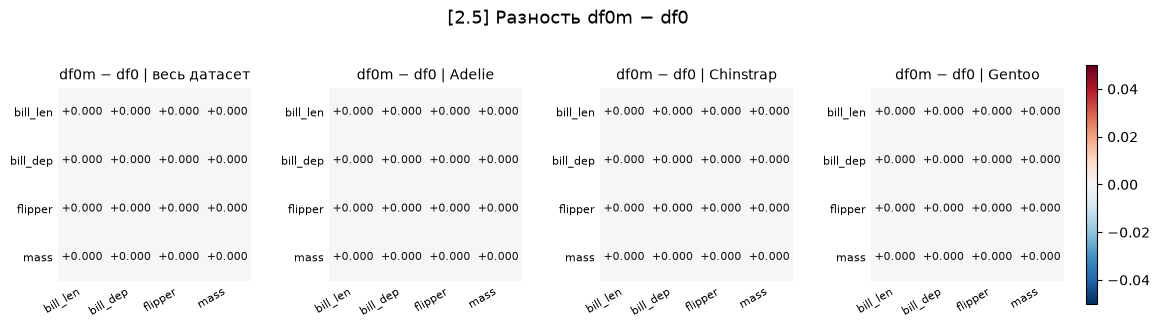

max |df0m − df0| по всем матрицам: 0.0


In [14]:
corr0  = pearson_tables(df0, FEATURES, CLASS_COL, "df0 | ")
corr0m = pearson_tables(df0m, FEATURES, CLASS_COL, "df0m | ")
plot_heatmaps(corr0, suptitle="[2.5] Пирсон, df0", short=SHORT)
plot_heatmaps(corr0m, suptitle="[2.5] Пирсон, df0m", short=SHORT)

diff = {k.replace("df0m | ", "df0m − df0 | "): corr0m[k] - corr0[k.replace("df0m", "df0")]
        for k in corr0m}
plot_heatmaps(diff, suptitle="[2.5] Разность df0m − df0", short=SHORT, vmin=-0.05, vmax=0.05,
              fmt="{:+.3f}")
print("max |df0m − df0| по всем матрицам:", max(float(np.nanmax(np.abs(d.to_numpy()))) for d in diff.values()))

Разность нулевая — и это ожидаемо: оба удалённых объекта не имеют **ни одного** из четырёх
значений, поэтому при парном удалении в df0 они и так не участвуют ни в одной паре. Фильтрация
df0m меняет корреляции только тогда, когда пропуски разбросаны по разным признакам у разных
объектов.

Важнее другое: корреляции на всём датасете и внутри видов заметно различаются. Например,
`bill_depth` на всём датасете коррелирует с массой и крылом **отрицательно**, а внутри каждого
вида — **положительно**: это парадокс Симпсона, его создаёт Gentoo (крупные пингвины с узким
клювом). Поэтому регрессии ниже строятся отдельно по классам.

## [2.6] Визуализация всех пар признаков (df0m)

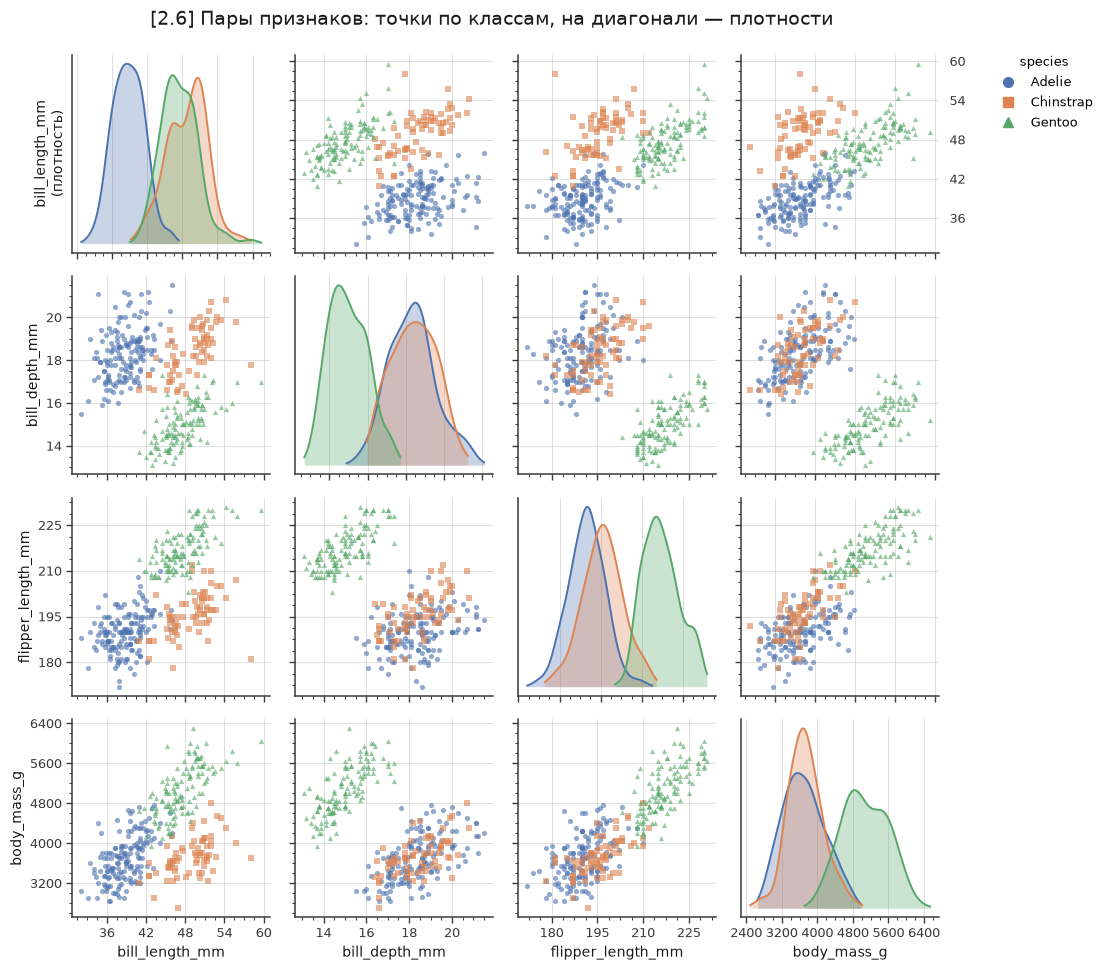

In [15]:
_ = pair_matrix(df0m, FEATURES, CLASS_COL, STYLE,
                suptitle="[2.6] Пары признаков: точки по классам, на диагонали — плотности")

## [2.7] Одиночный scatterplot с линией регрессии и полосами

Класс, пара признаков, уровень доверия и включение линии / доверительной / прогнозной полосы
задаются в форме «Параметры», оформление — в форме «Стиль графиков».

* **доверительная полоса** — где с вероятностью `CONF_LEVEL` лежит *средний* y при данном x;
* **прогнозная полоса** — где с той же вероятностью окажется *новое отдельное* наблюдение;
  она шире, так как добавляет разброс самих наблюдений вокруг линии.

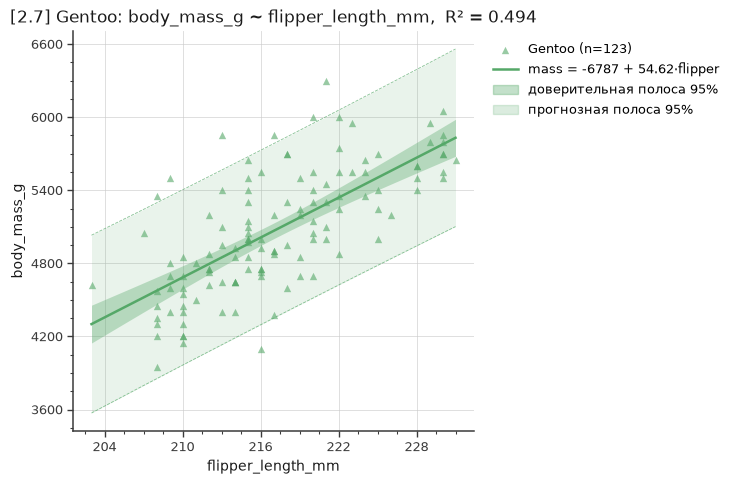

In [16]:
part = df0m[df0m[CLASS_COL] == REG_CLASS]
fit27 = fit_linreg(part[REG_X], part[REG_Y], alpha=ALPHA)
color = STYLE.colors_for(CLASSES)[REG_CLASS]
st = STYLE.derive(cell=5.2)

fig, ax = plt.subplots(figsize=(st.cell * 1.25, st.cell), dpi=st.dpi)
ax.scatter(fit27["x"], fit27["y"], s=st.point_size * 1.4, color=color,
           marker=st.markers_for(CLASSES)[REG_CLASS], alpha=st.point_alpha, linewidths=0,
           zorder=3, label=f"{REG_CLASS} (n={fit27['n']})")
draw_fit(ax, fit27, color, st, line=SHOW_REG_LINE, conf=SHOW_CONF_BAND, pred=SHOW_PRED_BAND,
         label=formula(fit27, SHORT[REG_X], SHORT[REG_Y]))
if SHOW_CONF_BAND:
    ax.fill_between([], [], [], color=color, alpha=st.conf_alpha, label=f"доверительная полоса {CONF_LEVEL:.0%}")
if SHOW_PRED_BAND:
    ax.fill_between([], [], [], color=color, alpha=st.pred_alpha * 1.6, label=f"прогнозная полоса {CONF_LEVEL:.0%}")
apply_axes_style(ax, st)
if st.show_axis_labels:
    ax.set_xlabel(REG_X, fontsize=st.axis_label_fontsize, color=st.label_color)
    ax.set_ylabel(REG_Y, fontsize=st.axis_label_fontsize, color=st.label_color)
if st.show_title:
    ax.set_title(f"[2.7] {REG_CLASS}: {REG_Y} ~ {REG_X},  R² = {fit27['r2']:.3f}",
                 fontsize=st.title_fontsize, color=st.label_color)
if st.show_legend:
    ax.legend(fontsize=st.legend_fontsize, frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1.0))
plt.show()

## [2.8] Пары признаков с регрессией по каждому классу

Повтор [2.6]: в каждой внедиагональной клетке (строка — y, столбец — x) для каждого вида своя
линия регрессии y ~ x и прогнозная полоса (`MATRIX_SHOW_PRED_BAND`), по желанию — и
доверительная (`MATRIX_SHOW_CONF_BAND`).

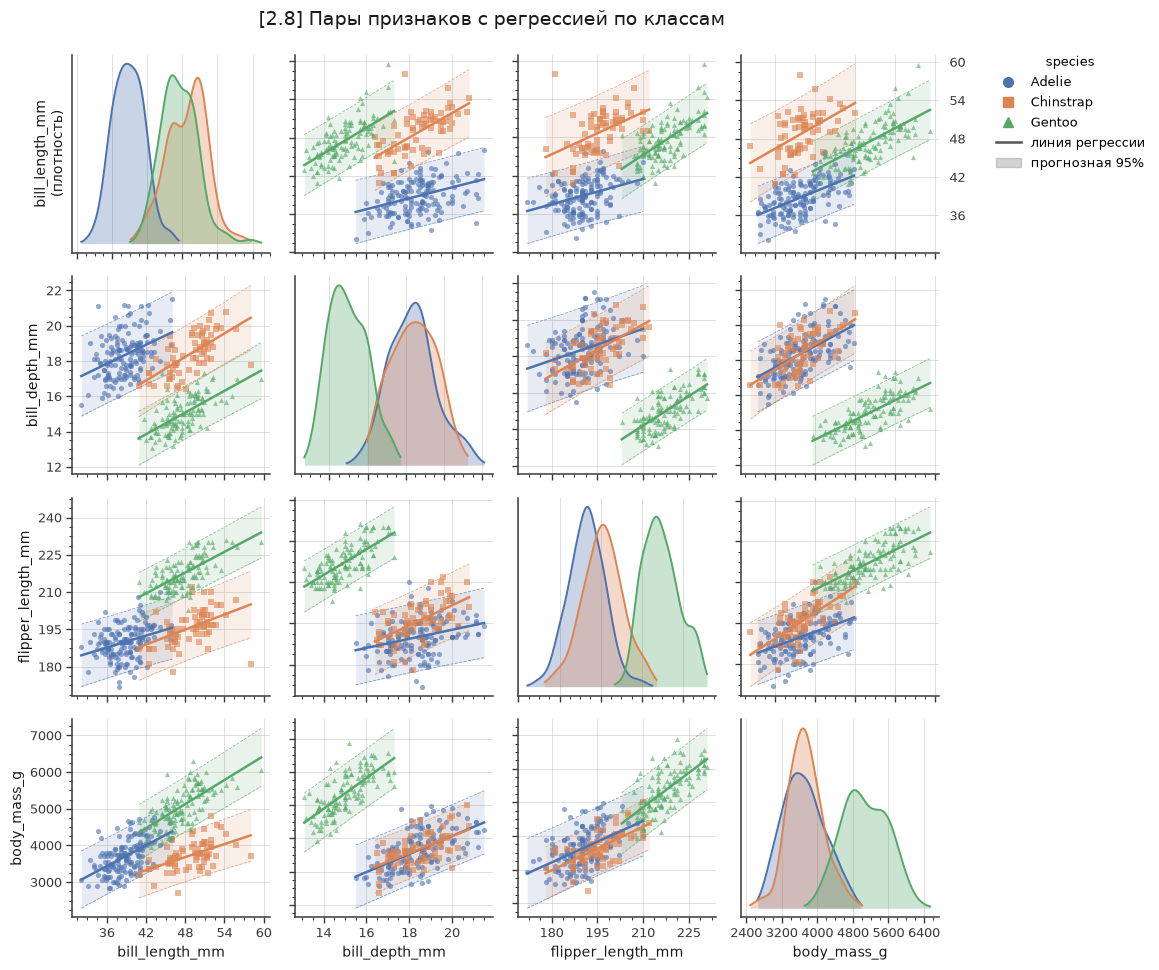

In [17]:
fits28 = pair_matrix(df0m, FEATURES, CLASS_COL, STYLE, regression=True,
                     show_pred=MATRIX_SHOW_PRED_BAND, show_conf=MATRIX_SHOW_CONF_BAND, alpha=ALPHA,
                     suptitle="[2.8] Пары признаков с регрессией по классам")

## [2.9] Формулы регрессий, R² и критерии Вальда, LR и score

Для каждой регрессии проверяется H₀: β₁ = 0 (наклон нулевой) против модели y = β₀ + β₁·x.
С RSS₀ — остаточной суммой квадратов модели только со свободным членом, RSS₁ — полной модели,
n — числом объектов, k = 2 параметрами и q = 1 ограничением:

| критерий | статистика (асимпт. χ²(q)) | F-форма |
|---|---|---|
| Вальд | W = n·(RSS₀ − RSS₁)/RSS₁ | F = W·(n − k)/(n·q) — классический F регрессии |
| LR | LR = n·ln(RSS₀/RSS₁) | F = LR·(n − k)/(n·q) |
| score (LM) | LM = n·(RSS₀ − RSS₁)/RSS₀ = n·R² | F = LM·(n − k)/(n·q) |

Для каждого выводится F, его степени свободы df1 = q = 1, df2 = n − 2 и p-значение по F(df1, df2).
Всегда W ≥ LR ≥ LM, поэтому при малых n вывод по трём критериям может различаться. Значения
сверены со statsmodels (`fvalue`, `compare_lr_test`, `compare_lm_test`).

In [18]:
def tests_table(rows):
    t = pd.DataFrame(rows)
    t.columns = pd.MultiIndex.from_tuples([c if isinstance(c, tuple) else (c, "") for c in t.columns])
    return t

fmt = {c: "{:.3g}" for c in [("Wald", "p"), ("LR", "p"), ("score", "p")]}
fmt.update({c: "{:.3f}" for c in [("R²", ""), ("Wald", "F"), ("LR", "F"), ("score", "F")]})

display(Markdown(f"**[2.7]** {formula(fit27, REG_X, REG_Y, 5)}"))
t27 = tests_table([tests_row(fit27, REG_CLASS, REG_X, REG_Y)])
display(t27.style.format(fmt).hide(axis="index"))

if fits28:
    display(Markdown("**[2.8]** все регрессии матрицы пар (y ~ x для каждого класса)"))
    t28 = tests_table([tests_row(f, lv, xf, yf) for (lv, xf, yf), f in fits28.items()])
    t28 = t28.sort_values([("класс", ""), ("y", ""), ("x", "")]).reset_index(drop=True)
    display(t28.style.format(fmt).hide(axis="index"))

    long = pd.DataFrame([{"критерий": name, "p": t["p(F)"]} for f in fits28.values()
                         for name, t in f["tests"].items()])
    n_signif = long.assign(signif=long["p"] < ALPHA).groupby("критерий")["signif"].sum()
    print(f"Значимых наклонов при α = {ALPHA:.2f} (из {len(fits28)}):", n_signif.to_dict())

**[2.7]** body_mass_g = -6787.3 + 54.623·flipper_length_mm

**[2.8]** все регрессии матрицы пар (y ~ x для каждого класса)

Значимых наклонов при α = 0.05 (из 36): {'LR': 36, 'Wald': 36, 'score': 36}


Регрессия y ~ x и x ~ y дают разные формулы, но одинаковые R² и тесты (для парной регрессии
R² = r²), поэтому в таблице 36 строк, а различных значений критериев — 18. При α = 0.05 все
наклоны значимы по всем трём критериям, а W ≥ LR ≥ LM выполняется в каждой строке. Самые слабые
связи — у Adelie с длиной крыла (R² ≈ 0.10–0.11 с глубиной и длиной клюва): значимы, но объясняют
лишь десятую часть разброса.

## [2.10] Raincloud выбранного признака по классам

Слева — точки с jittering («дождь»), справа — оценка плотности («облако»), между ними ящик:
белый прямоугольник — IQR (Q1–Q3), чёрная черта — медиана, цветная полоса внутри —
доверительный интервал (`RAIN_CI`: для медианы — перцентильный bootstrap, для среднего —
t-интервал, ромб — среднее).

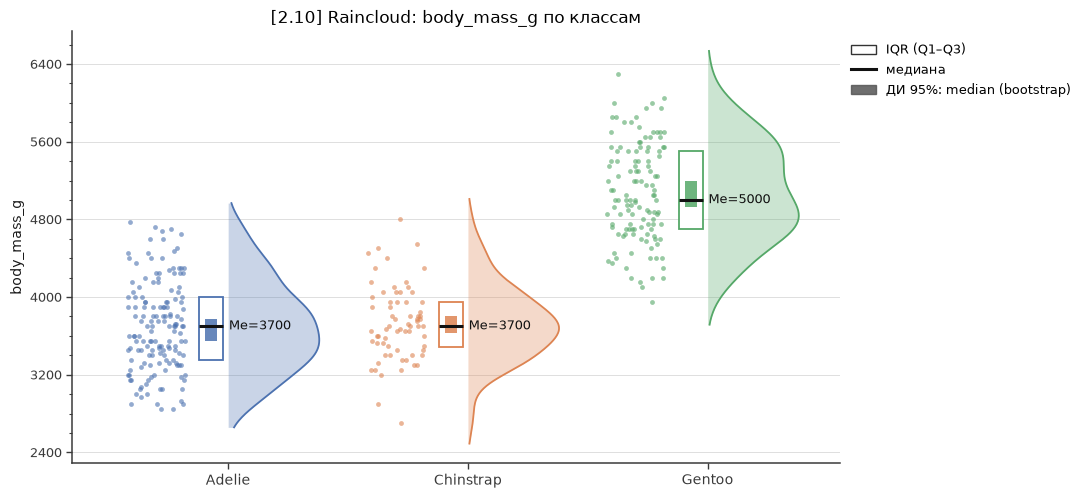

,n,медиана,Q1,Q3,IQR,оценка для ДИ,ДИ 95%: низ,ДИ 95%: верх
класс,,,,,,,,
Adelie,151,3700.0,3350.0,4000.0,650.0,3700.0,3550.0,3775.0
Chinstrap,68,3700.0,3487.5,3950.0,462.5,3700.0,3625.0,3800.0
Gentoo,123,5000.0,4700.0,5500.0,800.0,5000.0,4925.0,5200.0


In [19]:
raincloud_by_class(df0m, RAIN_FEATURE, CLASS_COL, STYLE.derive(cell=3.3), ci_kind=RAIN_CI,
                   level=CONF_LEVEL).round(3)

## [2.11] Однофакторный дисперсионный анализ (ANOVA)

H₀: средние значения признака `ANOVA_FEATURE` во всех классах равны.
F = (межгрупповой средний квадрат) / (внутригрупповой средний квадрат),
df1 = k − 1 (k — число классов), df2 = N − k (N — число объектов).
Для каждой пары классов — та же ANOVA на двух группах (df1 = 1, df2 = n₁ + n₂ − 2), плюс
поправка Бонферрони на 3 сравнения.

In [20]:
groups = {lv: df0m.loc[df0m[CLASS_COL] == lv, ANOVA_FEATURE].to_numpy(float) for lv in CLASSES}
N, k = sum(map(len, groups.values())), len(groups)
F_all, p_all = stats.f_oneway(*groups.values())

# сверка с statsmodels: классическая таблица ANOVA
aov = sm.stats.anova_lm(smf.ols(f"{ANOVA_FEATURE} ~ C({CLASS_COL})", data=df0m).fit(), typ=1)
assert np.isclose(aov["F"].iloc[0], F_all)
eta2 = aov["sum_sq"].iloc[0] / aov["sum_sq"].sum()

display(Markdown(f"**Признак:** `{ANOVA_FEATURE}`"))
display(pd.DataFrame({lv: {"n": len(g), "среднее": g.mean(), "ст. откл.": g.std(ddof=1)}
                      for lv, g in groups.items()}).T.round(3))
display(Markdown("**Все классы одновременно**"))
display(pd.DataFrame([{"сравнение": " vs ".join(CLASSES), "F": F_all, "df1": k - 1, "df2": N - k,
                       "p": p_all, "η²": eta2}]).style.format({"F": "{:.3f}", "p": "{:.3g}", "η²": "{:.3f}"})
        .hide(axis="index"))
display(Markdown("**Таблица ANOVA (statsmodels)**"))
display(aov.round(4))

rows = []
pairs = list(itertools.combinations(CLASSES, 2))
for a, b in pairs:
    F, p = stats.f_oneway(groups[a], groups[b])
    rows.append({"пара": f"{a} vs {b}", "F": F, "df1": 1, "df2": len(groups[a]) + len(groups[b]) - 2,
                 "p": p, "p (Бонферрони)": min(1.0, p * len(pairs)),
                 "разность средних": groups[a].mean() - groups[b].mean()})
display(Markdown("**Попарно**"))
display(pd.DataFrame(rows).style.format({"F": "{:.3f}", "p": "{:.3g}", "p (Бонферрони)": "{:.3g}",
                                         "разность средних": "{:+.3f}"}).hide(axis="index"))

**Признак:** `bill_length_mm`

,n,среднее,ст. откл.
Adelie,151.0,38.791,2.663
Chinstrap,68.0,48.834,3.339
Gentoo,123.0,47.505,3.082


**Все классы одновременно**

сравнение,F,df1,df2,p,η²
Adelie vs Chinstrap vs Gentoo,410.600,2,339,2.69e-91,0.708


**Таблица ANOVA (statsmodels)**

,df,sum_sq,mean_sq,F,PR(>F)
C(species),2.0,7194.3174,3597.1587,410.6003,0.0
Residual,339.0,2969.8881,8.7607,NaN,NaN


**Попарно**

пара,F,df1,df2,p,p (Бонферрони),разность средних
Adelie vs Chinstrap,566.532,1,217,2.01e-62,6.04e-62,-10.042
Adelie vs Gentoo,629.774,1,272,9.32e-73,2.8e-72,-8.713
Chinstrap vs Gentoo,7.670,1,189,0.00618,0.0185,+1.329


Для длины клюва различие видов огромно (F(2, 339) ≈ 411, η² ≈ 0.71: вид объясняет около 70%
разброса). Adelie резко отличается от обоих видов (на 9–10 мм), а Chinstrap и Gentoo близки:
разность средних ≈ 1.3 мм, F(1, 189) ≈ 7.7, p ≈ 0.019 даже после поправки Бонферрони — различие
есть, но на два порядка слабее. Поменяйте `ANOVA_FEATURE` в форме, чтобы посмотреть другие
признаки: например, по `body_mass_g` Adelie и Chinstrap неразличимы (p ≈ 0.61).

---
## [2.12**] Случайный гауссиан dfG: корреляция и регрессия

Отдельный блок, не зависящий от предыдущих ячеек (кроме импортов). Матрица ковариаций
строится случайно: Σ = R(θ)·diag(λ₁, λ₂)·R(θ)ᵀ со случайным углом поворота θ и случайными
собственными значениями (логарифмически-равномерными), поэтому форма и наклон облака каждый раз
разные. Сама матрица не выводится. Размер — случайный, от 10 до 100 объектов.

`SEED_G = -1` — новый датасет при каждом запуске; любое неотрицательное число фиксирует датасет.

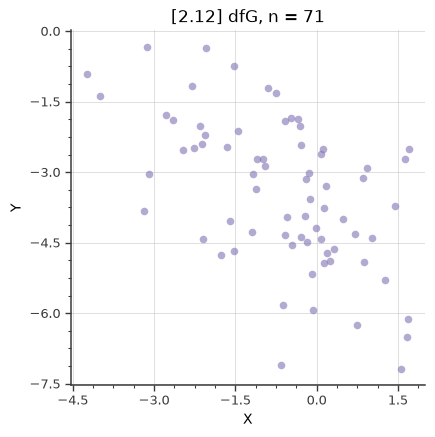

In [21]:
# @title [2.12] Генерация и первая визуализация dfG
SEED_G = -1  # @param {type:"integer"}

rng_g = np.random.default_rng(None if SEED_G < 0 else SEED_G)
n_g = int(rng_g.integers(10, 101))                               # 10..100 включительно
theta = rng_g.uniform(0, np.pi)
lam = 10 ** rng_g.uniform(-1.0, 1.0, size=2)                     # собственные значения
R = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
cov_g = R @ np.diag(lam) @ R.T                                   # симметричная положительно определённая
mean_g = rng_g.uniform(-5, 5, size=2)
dfG = pd.DataFrame(rng_g.multivariate_normal(mean_g, cov_g, size=n_g), columns=["X", "Y"])
dfG["class"] = "G"

stG = STYLE.derive(cell=4.6)
fig, ax = plt.subplots(figsize=(stG.cell, stG.cell), dpi=stG.dpi)
ax.scatter(dfG["X"], dfG["Y"], s=stG.point_size * 1.5, color=PALETTE[4], alpha=stG.point_alpha,
           linewidths=0)
apply_axes_style(ax, stG)
ax.set_xlabel("X", fontsize=stG.axis_label_fontsize)
ax.set_ylabel("Y", fontsize=stG.axis_label_fontsize)
if stG.show_title:
    ax.set_title(f"[2.12] dfG, n = {n_g}", fontsize=stG.title_fontsize)
plt.show()

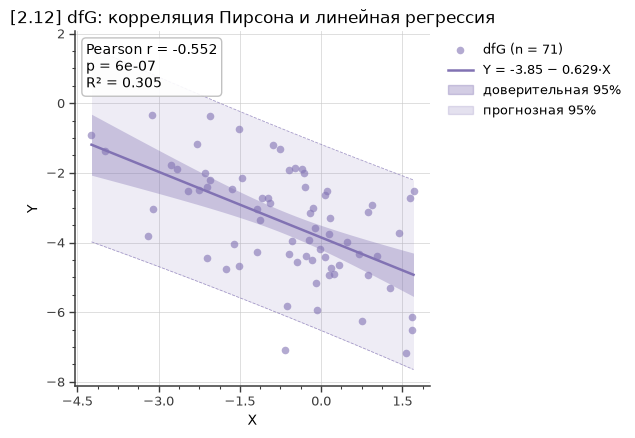

In [22]:
# @title [2.12] dfG с корреляцией Пирсона, регрессией и полосами
fitG = fit_linreg(dfG["X"], dfG["Y"], alpha=ALPHA)
r_g, p_r = stats.pearsonr(dfG["X"], dfG["Y"])
c = PALETTE[4]

fig, ax = plt.subplots(figsize=(stG.cell * 1.3, stG.cell), dpi=stG.dpi)
ax.scatter(fitG["x"], fitG["y"], s=stG.point_size * 1.5, color=c, alpha=stG.point_alpha,
           linewidths=0, zorder=3, label=f"dfG (n = {n_g})")
draw_fit(ax, fitG, c, stG, label=formula(fitG, "X", "Y", 3))
ax.fill_between([], [], [], color=c, alpha=stG.conf_alpha, label=f"доверительная {CONF_LEVEL:.0%}")
ax.fill_between([], [], [], color=c, alpha=stG.pred_alpha * 1.6, label=f"прогнозная {CONF_LEVEL:.0%}")
ax.text(0.03, 0.97, f"Pearson r = {r_g:.3f}\np = {p_r:.2g}\nR² = {fitG['r2']:.3f}",
        transform=ax.transAxes, va="top", fontsize=stG.axis_label_fontsize,
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="#BBB", alpha=0.9))
apply_axes_style(ax, stG)
ax.set_xlabel("X", fontsize=stG.axis_label_fontsize)
ax.set_ylabel("Y", fontsize=stG.axis_label_fontsize)
if stG.show_title:
    ax.set_title("[2.12] dfG: корреляция Пирсона и линейная регрессия", fontsize=stG.title_fontsize)
if stG.show_legend:
    ax.legend(fontsize=stG.legend_fontsize, frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1.0))
plt.show()